# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,844,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195
1,277,86,41,66,129,55,7,135,50,18,136,154,266,165,74,3,4,180,187
2,537,86,40,66,139,59,7,122,54,17,139,145,225,143,63,7,11,202,208
3,571,94,43,69,161,59,7,152,43,19,143,175,349,187,67,12,11,193,198
4,726,102,48,105,214,64,10,201,33,23,152,214,600,178,64,0,25,192,204
5,51,92,38,71,174,66,7,154,43,19,133,181,355,130,70,4,24,189,195
6,74,89,42,89,147,61,11,151,44,19,145,170,338,163,72,11,23,187,199
7,115,95,47,88,162,64,11,159,43,20,157,176,371,185,71,12,13,189,198
8,412,80,43,71,133,60,7,150,45,19,146,170,330,176,81,6,15,180,184
9,375,109,52,95,189,58,4,227,29,25,158,262,776,217,82,0,19,187,186


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,424.959927,93.500911,44.775956,81.719490,168.486339,61.704918,8.604736,168.081967,41.065574,20.513661,147.754098,188.005464,435.599271,174.306011,72.389800,6.459016,12.291439,189.051002,195.734062
std,242.174174,8.346647,5.959327,15.577145,33.462724,8.055713,4.793782,32.658689,7.727291,2.537006,13.972196,31.152468,172.951661,31.658205,7.707066,5.052341,8.756371,6.289920,7.497101
min,0.000000,73.000000,33.000000,40.000000,110.000000,47.000000,2.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,112.000000,60.000000,0.000000,0.000000,176.000000,182.000000
25%,222.000000,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,147.000000,34.000000,19.000000,137.000000,167.000000,319.000000,150.000000,67.000000,2.000000,5.000000,184.000000,190.000000
50%,425.000000,92.000000,44.000000,80.000000,166.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,177.000000,363.000000,173.000000,72.000000,5.000000,11.000000,189.000000,197.000000
75%,633.000000,99.000000,49.000000,96.000000,195.000000,65.000000,10.000000,196.000000,46.000000,23.000000,158.000000,215.000000,578.000000,196.000000,75.000000,9.000000,18.000000,193.000000,201.000000
max,844.000000,119.000000,58.000000,112.000000,333.000000,138.000000,55.000000,262.000000,61.000000,28.000000,188.000000,320.000000,987.000000,268.000000,135.000000,22.000000,38.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [18]:
import inspect
import warnings
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, roc_curve, auc

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

#Столбец 0 — это просто номер строки, а не признак.
print('Столбец 0 уникален:', len(np.unique(data[:, 0])) == len(data))
X_train_f = X_train[:, 1:].astype(float)
X_test_f = X_test[:, 1:].astype(float)

#Целевая переменная - строки ('bus', 'opel', 'saab', 'van'). Кодируем в 0..3
#нужно для LightGBM и для удобного построения ROC).
le = LabelEncoder().fit(y_train)
y_train_enc = le.transform(y_train)
y_test_enc = le.transform(y_test)
CLASSES = le.classes_
print('Классы:', dict(zip(CLASSES, range(len(CLASSES)))))
print('Баланс классов в train:', np.bincount(y_train_enc))

#Признаки в очень разных масштабах -> стандартизация.
#Scaler обучаем ТОЛЬКО на train, test лишь трансформируем.
print('Std признаков до масштабирования:', np.round(X_train_f.std(axis=0), 1))
scaler = StandardScaler().fit(X_train_f)
X_train_sc = scaler.transform(X_train_f)
X_test_sc = scaler.transform(X_test_f)

#Фиксированные гиперпараметры логистической регрессии из задания.
#В sklearn >= 1.7 аргумента multi_class больше нет (multinomial там используется по умолчанию), поэтому передаём его только если текущая версия его поддерживает.
LR_FIXED = dict(solver='saga', tol=1e-3, max_iter=500, random_state=RANDOM_STATE)
if 'multi_class' in inspect.signature(LogisticRegression).parameters:
    LR_FIXED['multi_class'] = 'multinomial'

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate(model, X_te, y_te=y_test_enc, name=''):
    """Accuracy и macro-F1 на test."""
    pred = model.predict(X_te)
    acc = accuracy_score(y_te, pred)
    f1 = f1_score(y_te, pred, average='macro')
    print(f'{name}: accuracy = {acc:.4f}, f1 (macro) = {f1:.4f}')
    return acc, f1


def plot_multiclass_roc(y_true, proba, title='ROC curves'):
    """ROC через scikitplot, а если он не установлен/несовместим с scipy — вручную (one-vs-rest)."""
    try:
        import scikitplot
        scikitplot.metrics.plot_roc(CLASSES[y_true], proba, title=title, figsize=(7, 6))
        plt.show()
        return
    except Exception:
        pass
    y_bin = label_binarize(y_true, classes=range(len(CLASSES)))
    plt.figure(figsize=(7, 6))
    fprs, tprs = [], []
    for i, cls in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        fprs.append(fpr); tprs.append(tpr)
        plt.plot(fpr, tpr, lw=1.5, label=f'class {cls} (AUC = {auc(fpr, tpr):.3f})')
    fpr, tpr, _ = roc_curve(y_bin.ravel(), proba.ravel())
    plt.plot(fpr, tpr, ':', lw=3, label=f'micro-average (AUC = {auc(fpr, tpr):.3f})')
    grid = np.unique(np.concatenate(fprs))
    mean_tpr = np.mean([np.interp(grid, f, t) for f, t in zip(fprs, tprs)], axis=0)
    plt.plot(grid, mean_tpr, ':', lw=3, label=f'macro-average (AUC = {auc(grid, mean_tpr):.3f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(title); plt.legend(loc='lower right'); plt.grid(alpha=.3)
    plt.show()

Столбец 0 уникален: True
Классы: {'bus': 0, 'opel': 1, 'saab': 2, 'van': 3}
Баланс классов в train: [146 135 144 124]
Std признаков до масштабирования: [  8.3   6.   15.6  33.4   8.    4.8  32.6   7.7   2.5  14.   31.1 172.8
  31.6   7.7   5.    8.7   6.3   7.5]


**Выводы по 2.0.**
* Пропусков нет, классы примерно сбалансированы, поэтому дополнительная балансировка не нужна. В качестве `f1` используется **macro-F1**.
* В ячейке с `train_test_split` нет `random_state`, поэтому при каждом перезапуске разбиение (и результат счета) немного меняется. Выводы при этом одни и те же.*

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/l

Лучшие параметры: {'lr__C': 30, 'lr__penalty': 'l2'}
CV f1 (macro) = 0.7948
LogReg (test): accuracy = 0.8081, f1 (macro) = 0.8065


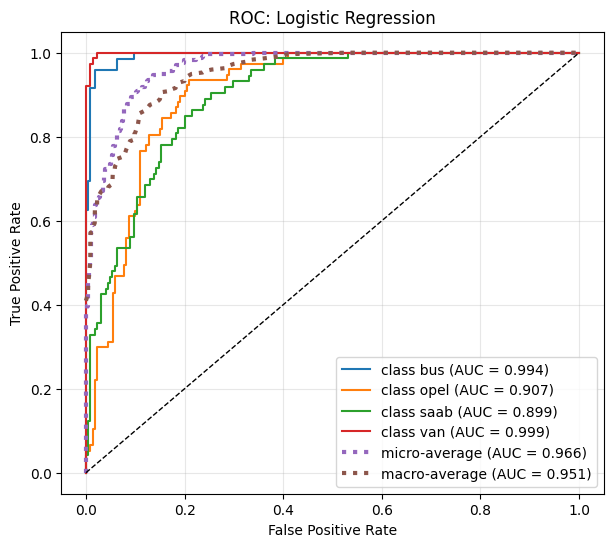

In [20]:
#Масштабирование внутри Pipeline, чтобы на кросс-валидации scaler обучался только на train-фолдах.
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(**LR_FIXED)),
])
lr_grid = {
    'lr__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000],
    'lr__penalty': ['l1', 'l2'],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
lr_search.fit(X_train_f, y_train_enc)
print('Лучшие параметры:', lr_search.best_params_)
print(f'CV f1 (macro) = {lr_search.best_score_:.4f}')

lr_best = lr_search.best_estimator_
lr_acc, lr_f1 = evaluate(lr_best, X_test_f, name='LogReg (test)')
plot_multiclass_roc(y_test_enc, lr_best.predict_proba(X_test_f), title='ROC: Logistic Regression')

**Выводы по 2.1.** 
* Перебором по сетке (`C` × `penalty`, 5-fold стратифицированная CV, метрика macro-F1) найдены параметры логистической регрессии. На test получаем accuracy - 0.8081 и macro-F1 = 0.8065.
* По ROC-кривым классы `bus` и `van` отделяются. Основные ошибки приходятся на пару `opel` / `saab`.

In [8]:
# You might use this command to install scikit-plot. 
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding 
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot. 

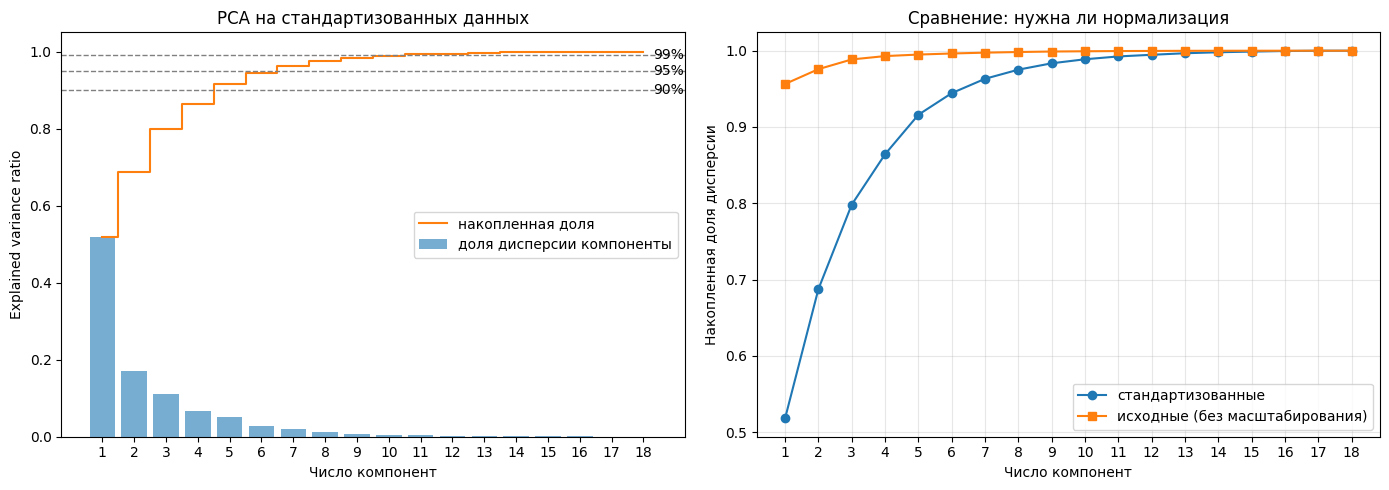

Компонент для 90% дисперсии: 5
Компонент для 95% дисперсии: 7
Компонент для 99% дисперсии: 11
Без масштабирования 1-я компонента объясняет 95.6% — и почти целиком состоит из признака с макс. дисперсией (индекс 12 в исходной таблице)


In [21]:
from sklearn.decomposition import PCA

#PCA на стандартизованных данных и для сравнения на исходных.
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_sc)
pca_raw = PCA(random_state=RANDOM_STATE).fit(X_train_f)

evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
k = np.arange(1, len(evr) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(k, evr, alpha=.6, label='доля дисперсии компоненты')
axes[0].step(k, cum, where='mid', color='C1', label='накопленная доля')
for thr in (0.90, 0.95, 0.99):
    axes[0].axhline(thr, ls='--', lw=1, color='grey')
    axes[0].text(len(k) + .3, thr, f'{thr:.0%}', va='center')
axes[0].set_xticks(k); axes[0].set_xlabel('Число компонент'); axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('PCA на стандартизованных данных'); axes[0].legend(loc='center right')

axes[1].plot(k, cum, 'o-', label='стандартизованные')
axes[1].plot(k, np.cumsum(pca_raw.explained_variance_ratio_), 's-', label='исходные (без масштабирования)')
axes[1].set_xticks(k); axes[1].set_xlabel('Число компонент'); axes[1].set_ylabel('Накопленная доля дисперсии')
axes[1].set_title('Сравнение: нужна ли нормализация'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

for thr in (0.90, 0.95, 0.99):
    print(f'Компонент для {thr:.0%} дисперсии: {np.argmax(cum >= thr) + 1}')
print('Без масштабирования 1-я компонента объясняет', f'{pca_raw.explained_variance_ratio_[0]:.1%}',
      '— и почти целиком состоит из признака с макс. дисперсией (индекс',
      np.argmax(np.abs(pca_raw.components_[0])) + 1, 'в исходной таблице)')

**Выводы по 2.2.** 

* На стандартизованных данных первая компонента объясняет ~50% дисперсии, первые две ~75%. Дальше вклад компонент быстро падает.
* На правом графике видно, что без масштабирования первая компонента объясняет ~95+% дисперсии. Но это артефакт: она почти полностью совпадает с одним признаком, у которого самая большая дисперсия (std = 180).

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [23]:
N_COMPONENTS = int(np.argmax(cum >= 0.95) + 1)   #минимальное число компонент, дающее >= 95% дисперсии
print('Выбрано компонент:', N_COMPONENTS, f'(объяснено {cum[N_COMPONENTS - 1]:.2%} дисперсии)')

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
pca.fit(X_train_sc)                      #fit только на train
X_train_pca = pca.transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)
print(X_train_pca.shape, X_test_pca.shape)

Выбрано компонент: 7 (объяснено 96.32% дисперсии)
(549, 7) (297, 7)


**Выводы по 2.3.** 
* Число компонент выбрано как минимальное, при котором объясняется ≥ 95% дисперсии: **7 компонент**.
* **Нужно ли нормализовать данные? - Да.** PCA ищет направления максимальной дисперсии, поэтому без масштабирования результат определяется единицами измерения признаков, а не структурой данных. Один признак с большим разбросом забирает себе почти всю первую компоненту (см. правый график в 2.2). PCA обучен (`fit`) только на train, а test только трансформирован (`transform`).

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/k.kanishchev/Library/Python/3.9/lib/python/site-packages/sklearn/l

Лучшие параметры: {'lr__C': 3, 'lr__penalty': 'l1'}
CV f1 (macro) = 0.6414
LogReg + PCA (test): accuracy = 0.6229, f1 (macro) = 0.6145


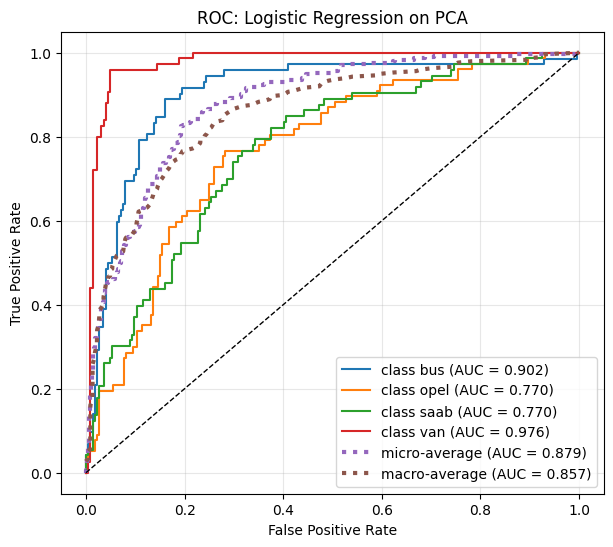


Сравнение: без PCA acc=0.8081, f1=0.8065 | с PCA acc=0.6229, f1=0.6145


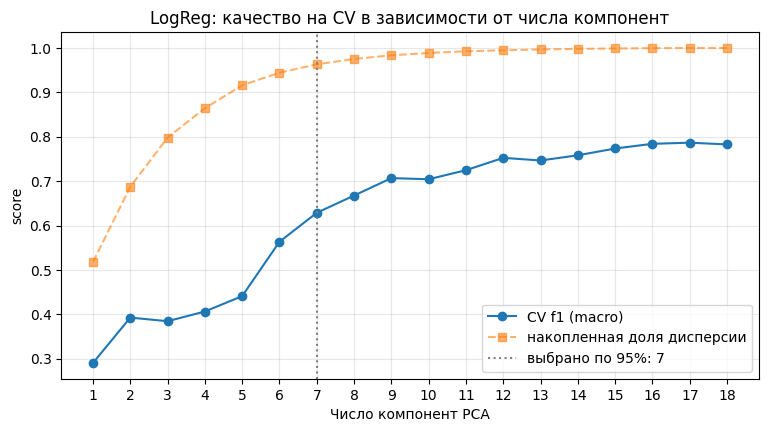

CV f1 по числу компонент: {1: 0.291, 2: 0.393, 3: 0.385, 4: 0.407, 5: 0.441, 6: 0.564, 7: 0.629, 8: 0.668, 9: 0.707, 10: 0.704, 11: 0.725, 12: 0.753, 13: 0.747, 14: 0.758, 15: 0.774, 16: 0.784, 17: 0.787, 18: 0.783}


In [24]:
#Компоненты PCA имеют разную дисперсию, поэтому перед регрессией ещё раз стандартизуем их (иначе регуляризация штрафует слабые компоненты сильнее).
lr_pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(**LR_FIXED)),
])
lr_pca_search = GridSearchCV(lr_pca_pipe, lr_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
lr_pca_search.fit(X_train_pca, y_train_enc)
print('Лучшие параметры:', lr_pca_search.best_params_)
print(f'CV f1 (macro) = {lr_pca_search.best_score_:.4f}')

lr_pca_best = lr_pca_search.best_estimator_
lr_pca_acc, lr_pca_f1 = evaluate(lr_pca_best, X_test_pca, name='LogReg + PCA (test)')
plot_multiclass_roc(y_test_enc, lr_pca_best.predict_proba(X_test_pca), title='ROC: Logistic Regression on PCA')

print(f'\nСравнение: без PCA acc={lr_acc:.4f}, f1={lr_f1:.4f} | с PCA acc={lr_pca_acc:.4f}, f1={lr_pca_f1:.4f}')

#Дополнительно: как качество логрегрессии (CV на train) зависит от числа компонент PCA.
from sklearn.model_selection import cross_val_score
best_lr_params = {k.replace('lr__', ''): v for k, v in lr_search.best_params_.items()}
n_comp_grid = list(range(1, X_train_f.shape[1] + 1))
cv_by_ncomp = [cross_val_score(Pipeline([('scaler', StandardScaler()),
                                         ('pca', PCA(n_components=nc, random_state=RANDOM_STATE)),
                                         ('scaler2', StandardScaler()),
                                         ('lr', LogisticRegression(**LR_FIXED, **best_lr_params))]),
                               X_train_f, y_train_enc, cv=CV, scoring='f1_macro').mean()
               for nc in n_comp_grid]
plt.figure(figsize=(9, 4.5))
plt.plot(n_comp_grid, cv_by_ncomp, 'o-', label='CV f1 (macro)')
plt.plot(n_comp_grid, cum, 's--', alpha=.6, label='накопленная доля дисперсии')
plt.axvline(N_COMPONENTS, ls=':', color='grey', label=f'выбрано по 95%: {N_COMPONENTS}')
plt.xticks(n_comp_grid); plt.xlabel('Число компонент PCA'); plt.ylabel('score')
plt.title('LogReg: качество на CV в зависимости от числа компонент'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('CV f1 по числу компонент:', {nc: round(float(v), 3) for nc, v in zip(n_comp_grid, cv_by_ncomp)})

**Выводы по 2.4.** 

* После PCA до 7 компонент качество логистической регрессии заметно падает: accuracy in (0.60–0.66) (перезапуски) против 0.81~ без PCA.
* Причину показывает крайний график. PCA — метод без учителя: он сохраняет направления с наибольшей дисперсией, но не обязательно те, по которым различаются классы. Информация, которая отличает `opel` от `saab`, лежит в компонентах с малой дисперсией, и правило 95% дисперсии их отбрасывает. CV-качество растёт почти монотонно с числом компонент и выходит на уровень модели без PCA только при ~15-18 компонентах.
* Для этой задачи PCA как способ сжатия признаков не помогает.

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

Оптимальная глубина: 12 | CV f1 (macro) = 0.6682


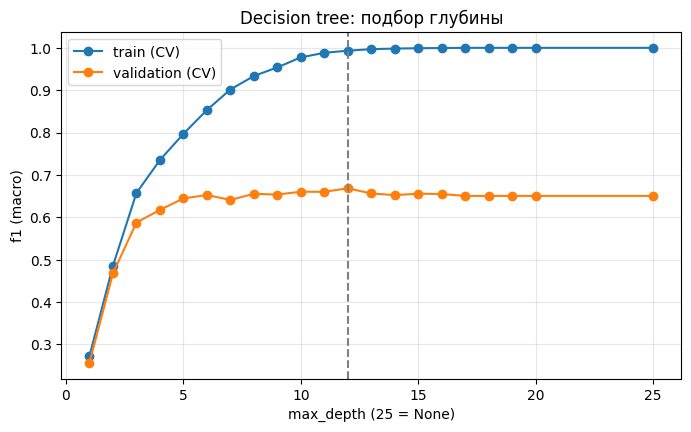

Decision tree (test): accuracy = 0.7037, f1 (macro) = 0.7086


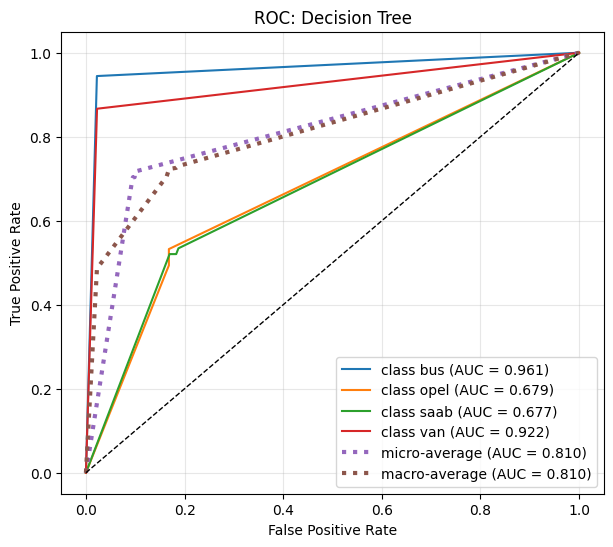

In [25]:
from sklearn.tree import DecisionTreeClassifier

#Дереву масштаб признаков не важен, обучаем на исходных признаках (без столбца-индекса).
dt_grid = {'max_depth': list(range(1, 21)) + [None]}
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid,
                         cv=CV, scoring='f1_macro', n_jobs=-1, return_train_score=True)
dt_search.fit(X_train_f, y_train_enc)
BEST_DEPTH = dt_search.best_params_['max_depth']
print('Оптимальная глубина:', BEST_DEPTH, f'| CV f1 (macro) = {dt_search.best_score_:.4f}')

res = pd.DataFrame(dt_search.cv_results_)
depths = [d if d is not None else 25 for d in res['param_max_depth']]
plt.figure(figsize=(8, 4.5))
plt.plot(depths, res['mean_train_score'], 'o-', label='train (CV)')
plt.plot(depths, res['mean_test_score'], 'o-', label='validation (CV)')
plt.axvline(BEST_DEPTH if BEST_DEPTH is not None else 25, ls='--', color='grey')
plt.xlabel('max_depth (25 = None)'); plt.ylabel('f1 (macro)'); plt.title('Decision tree: подбор глубины')
plt.legend(); plt.grid(alpha=.3); plt.show()

dt_best = dt_search.best_estimator_
dt_acc, dt_f1 = evaluate(dt_best, X_test_f, name='Decision tree (test)')
plot_multiclass_roc(y_test_enc, dt_best.predict_proba(X_test_f), title='ROC: Decision Tree')

**Выводы по 2.5.** 

* Глубина дерева подобрана по CV. Оптимум обычно лежит в районе `max_depth` - 7–11 и зависит от разбиения. На графике видна классическая картина: качество на train растёт с глубиной до 1.0, а на валидации выходит на плато ~0.65. Более глубокие деревья переобучаются.
* На test одно дерево заметно уступает логистической регрессии. Одно дерево — модель с высокой дисперсией, и её качество сильно зависит от конкретной выборки.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble? 

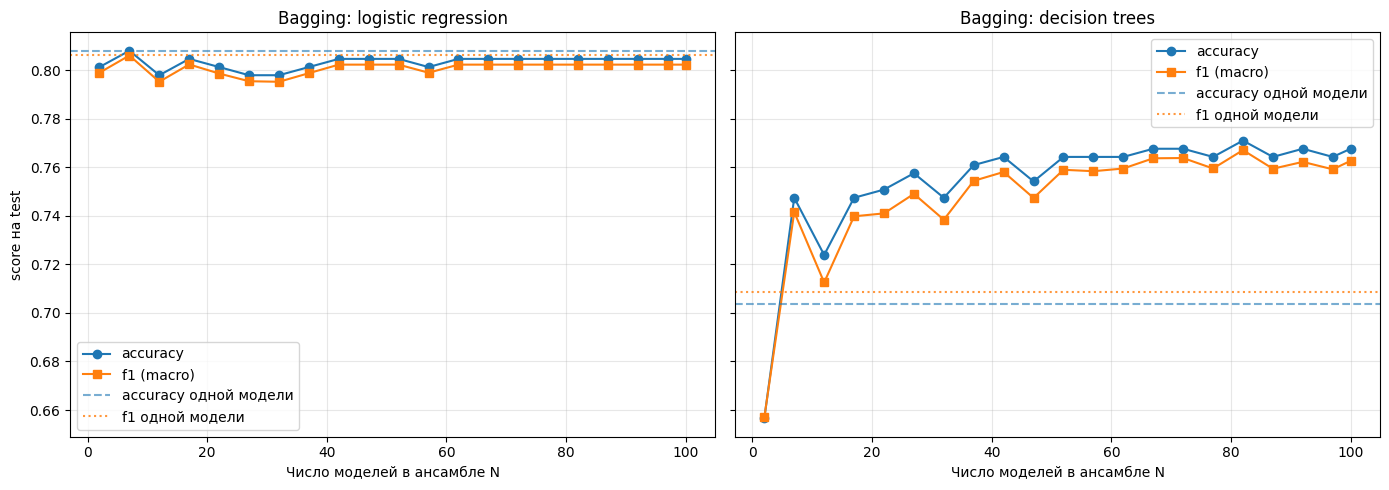

,N,LR acc,LR f1,DT acc,DT f1
0,2,0.8013,0.7990,0.6566,0.6569
1,7,0.8081,0.8061,0.7475,0.7416
2,12,0.7980,0.7953,0.7239,0.7126
3,17,0.8047,0.8024,0.7475,0.7398
4,22,0.8013,0.7987,0.7508,0.7410
5,27,0.7980,0.7955,0.7576,0.7491
6,32,0.7980,0.7953,0.7475,0.7384
7,37,0.8013,0.7988,0.7609,0.7545
8,42,0.8047,0.8023,0.7643,0.7581
9,47,0.8047,0.8023,0.7542,0.7474


In [26]:
from sklearn.base import clone

N_MAX = 100
N_GRID = list(range(2, N_MAX + 1, 5)) + [N_MAX]

rng = np.random.RandomState(RANDOM_STATE)
n = len(X_train_f)
boot_idx = [rng.randint(0, n, n) for _ in range(N_MAX)]


def bagging_curve(base_model, X_tr, X_te):
    """Обучаем N_MAX моделей с нуля на бутстреп-выборках, затем усредняем вероятности первых N."""
    probas = []
    for idx in boot_idx:
        m = clone(base_model).fit(X_tr[idx], y_train_enc[idx])
        p = np.zeros((len(X_te), len(CLASSES)))
        p[:, m.classes_] = m.predict_proba(X_te)
        probas.append(p)
    probas = np.cumsum(probas, axis=0)
    acc, f1 = [], []
    for N in N_GRID:
        pred = probas[N - 1].argmax(axis=1)
        acc.append(accuracy_score(y_test_enc, pred))
        f1.append(f1_score(y_test_enc, pred, average='macro'))
    return np.array(acc), np.array(f1)


#Базовые модели - с оптимальными гиперпараметрами из 2.1 и 2.5
bag_lr_acc, bag_lr_f1 = bagging_curve(lr_best, X_train_f, X_test_f)
bag_dt_acc, bag_dt_f1 = bagging_curve(dt_best, X_train_f, X_test_f)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, acc, f1, single) in zip(axes, [
        ('Bagging: logistic regression', bag_lr_acc, bag_lr_f1, (lr_acc, lr_f1)),
        ('Bagging: decision trees', bag_dt_acc, bag_dt_f1, (dt_acc, dt_f1))]):
    ax.plot(N_GRID, acc, 'o-', label='accuracy')
    ax.plot(N_GRID, f1, 's-', label='f1 (macro)')
    ax.axhline(single[0], ls='--', color='C0', alpha=.6, label='accuracy одной модели')
    ax.axhline(single[1], ls=':', color='C1', alpha=.8, label='f1 одной модели')
    ax.set_xlabel('Число моделей в ансамбле N'); ax.set_title(name); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('score на test')
plt.tight_layout(); plt.show()

bag_table = pd.DataFrame({'N': N_GRID, 'LR acc': bag_lr_acc, 'LR f1': bag_lr_f1,
                          'DT acc': bag_dt_acc, 'DT f1': bag_dt_f1}).round(4)
bag_table

**Выводы по 2.6.**

* **Логистическая регрессия.** Бэггинг почти ничего не даёт: прирост в пределах 1%, кривая выходит на плато уже при N = 7–15. Логрегрессия — устойчивая модель с низкой дисперсией, а бэггинг уменьшает именно дисперсию, поэтому усреднять почти нечего. 
* **Деревья решений.** Здесь выигрыш большой: >5% по сравнению с одним деревом. Качество быстро растёт примерно до N = 20–40, после этого кривая выходит на плато и колеблется в пределах +-1%. Эти колебания — шум конечной тестовой выборки, а не реальный эффект.
* **Оптимальное число моделей.** Для деревьев — ~30–50, для логрегрессии ~10–20. Дальше качество практически не растет, а время обучения увеличивается линейно. Увеличение N не приводит к переобучению: оно лишь уменьшает дисперсию усредненного прогноза, которая убывает примерно как 1/N плюс неустранимая часть, связанная с корреляцией моделей.

In [27]:
#Подходят ли параметры дерева из 2.5 для бэггинга? Сравним разные глубины (включая неограниченную) при фиксированном N = 100 деревьев. 
from sklearn.ensemble import BaggingClassifier

rows = []
for depth in sorted({BEST_DEPTH, 5, 8, 12, 16, None}, key=lambda d: 1e9 if d is None else d):
    bag = BaggingClassifier(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
                            n_estimators=100, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
    bag.fit(X_train_f, y_train_enc)
    pred = bag.predict(X_test_f)
    rows.append({'max_depth': str(depth), 'OOB accuracy': bag.oob_score_,
                 'test accuracy': accuracy_score(y_test_enc, pred),
                 'test f1': f1_score(y_test_enc, pred, average='macro')})
pd.DataFrame(rows).round(4)

,max_depth,OOB accuracy,test accuracy,test f1
0,5,0.7049,0.7508,0.7390
1,8,0.7286,0.7643,0.7585
2,12,0.7432,0.7677,0.7623
3,16,0.7395,0.7609,0.7536
4,None,0.7413,0.7609,0.7542


**Оптимальность** 

* Скорее нет. Глубина из 2.5 подбиралась для **одиночного** дерева, где нужно балансировать смещение (bias) и дисперсию, поэтому дерево специально ограничено. Бэггинг сам уменьшает дисперсию, но не смещение. Поэтому в ансамбль лучше брать более глубокие деревья (вплоть до `max_depth=None`) с низким смещением, а их высокую дисперсию погасит усреднение.
* В таблице (OOB-оценка и test) это видно так: неглубокие деревья (5) в ансамбле хуже, а глубокие (12, 16, `None`) не хуже оптимальной глубины из 2.5 или немного лучше. Разница невелика, потому что на этих данных дерево глубже ~12 уже почти не растёт.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

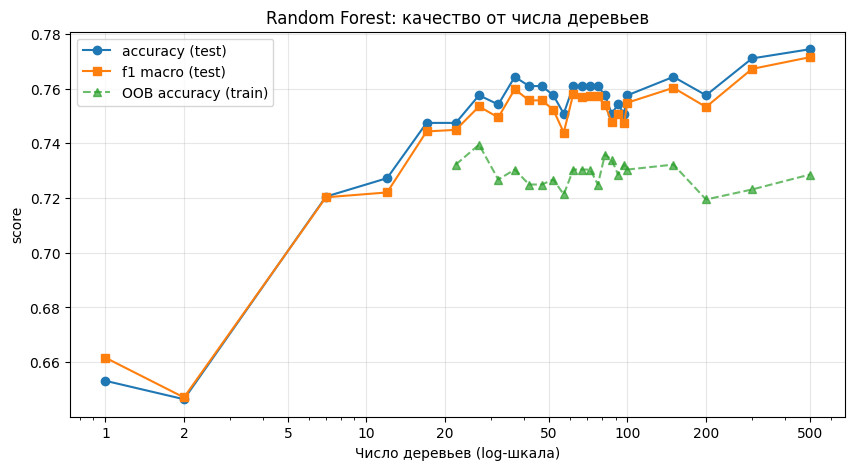

 n_trees    acc     f1  OOB acc
       1 0.6532 0.6617      NaN
       2 0.6465 0.6471      NaN
       7 0.7205 0.7203      NaN
      12 0.7273 0.7221      NaN
      17 0.7475 0.7443      NaN
      22 0.7475 0.7449   0.7322
      27 0.7576 0.7535   0.7395
      32 0.7542 0.7495   0.7268
      37 0.7643 0.7598   0.7304
      42 0.7609 0.7557   0.7250
      47 0.7609 0.7557   0.7250
      52 0.7576 0.7523   0.7268
      57 0.7508 0.7439   0.7213
      62 0.7609 0.7581   0.7304
      67 0.7609 0.7570   0.7304
      72 0.7609 0.7573   0.7304
      77 0.7609 0.7572   0.7250
      82 0.7576 0.7540   0.7359
      87 0.7508 0.7479   0.7341
      92 0.7542 0.7508   0.7286
      97 0.7508 0.7473   0.7322
     100 0.7576 0.7549   0.7304
     150 0.7643 0.7603   0.7322
     200 0.7576 0.7533   0.7195
     300 0.7710 0.7672   0.7231
     500 0.7744 0.7715   0.7286

Выбранное число деревьев: 27
Random forest, 27 trees (test): accuracy = 0.7576, f1 (macro) = 0.7535


In [29]:
from sklearn.ensemble import RandomForestClassifier

RF_GRID = [1] + list(range(2, 101, 5)) + [100, 150, 200, 300, 500]
rf_acc, rf_f1, rf_oob = [], [], []
for n_trees in RF_GRID:
    rf = RandomForestClassifier(n_estimators=n_trees, oob_score=n_trees >= 20,
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_f, y_train_enc)
    pred = rf.predict(X_test_f)
    rf_acc.append(accuracy_score(y_test_enc, pred))
    rf_f1.append(f1_score(y_test_enc, pred, average='macro'))
    rf_oob.append(rf.oob_score_ if n_trees >= 20 else np.nan)

plt.figure(figsize=(10, 5))
plt.plot(RF_GRID, rf_acc, 'o-', label='accuracy (test)')
plt.plot(RF_GRID, rf_f1, 's-', label='f1 macro (test)')
plt.plot(RF_GRID, rf_oob, '^--', alpha=.7, label='OOB accuracy (train)')
plt.xscale('log'); plt.xticks([1, 2, 5, 10, 20, 50, 100, 200, 500], [1, 2, 5, 10, 20, 50, 100, 200, 500])
plt.xlabel('Число деревьев (log-шкала)'); plt.ylabel('score'); plt.title('Random Forest: качество от числа деревьев')
plt.legend(); plt.grid(alpha=.3); plt.show()

rf_table = pd.DataFrame({'n_trees': RF_GRID, 'acc': rf_acc, 'f1': rf_f1, 'OOB acc': rf_oob}).round(4)
print(rf_table.to_string(index=False))

#Оптимальное число деревьев выбираем по OOB: минимальное N, при котором OOB-accuracy не более чем на 0.5% ниже максимальной.
oob = np.array(rf_oob)
RF_N_TREES = RF_GRID[int(np.nanargmax(oob >= np.nanmax(oob) - 0.005))]
print('\nВыбранное число деревьев:', RF_N_TREES)
rf_best = RandomForestClassifier(n_estimators=RF_N_TREES, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_f, y_train_enc)
rf_acc_best, rf_f1_best = evaluate(rf_best, X_test_f, name=f'Random forest, {RF_N_TREES} trees (test)')

**Выводы по 2.7.** 

* Качество быстро растёт при увеличении числа деревьев примерно до 30, затем выходит на плато (accuracy = 0.74–0.78 на разных разбиениях). Дальше колебания на уровне шума. Как и в бэггинге, добавление деревьев не вызывает переобучения, только увеличивает время работы.
* На этих данных RF не обгоняет бэггинг деревьев и уступает логрегрессии. Признаков мало, и они сильно скоррелированы, поэтому ограничение `max_features='sqrt'` (~4 признака на узел) скорее мешает, чем помогает.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it? 

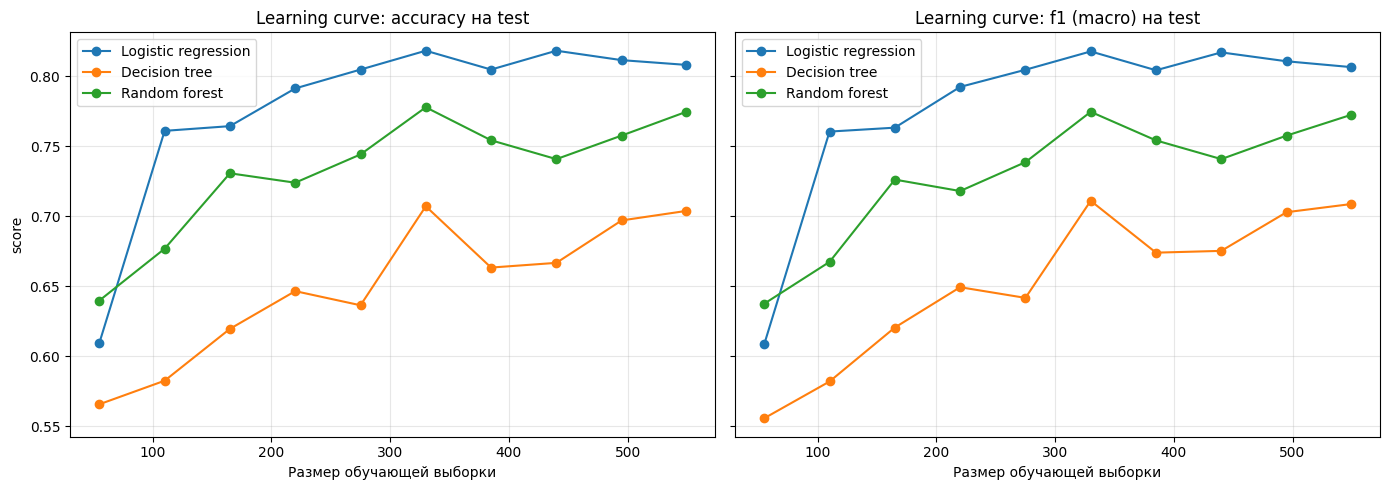

,train size,Logistic regression f1,Decision tree f1,Random forest f1
0,55,0.6086,0.5557,0.6375
1,110,0.7604,0.5819,0.6674
2,165,0.7632,0.6205,0.7261
3,220,0.7923,0.6493,0.7179
4,275,0.8046,0.6416,0.7386
5,330,0.8177,0.7110,0.7745
6,385,0.8042,0.6739,0.7541
7,440,0.8170,0.6752,0.7408
8,495,0.8106,0.7028,0.7575
9,549,0.8065,0.7086,0.7723


In [30]:
#Делим train на 10 почти равных частей со стратификацией
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
parts = [test_idx for _, test_idx in skf10.split(X_train_f, y_train_enc)]

models = {
    'Logistic regression': lr_best,
    'Decision tree': dt_best,
    'Random forest': rf_best,
}
sizes, lc = [], {name: {'acc': [], 'f1': []} for name in models}
for k_parts in range(1, 11):
    idx = np.concatenate(parts[:k_parts])
    sizes.append(len(idx))
    for name, model in models.items():
        m = clone(model).fit(X_train_f[idx], y_train_enc[idx])
        pred = m.predict(X_test_f)
        lc[name]['acc'].append(accuracy_score(y_test_enc, pred))
        lc[name]['f1'].append(f1_score(y_test_enc, pred, average='macro'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric, title in zip(axes, ['acc', 'f1'], ['accuracy', 'f1 (macro)']):
    for name in models:
        ax.plot(sizes, lc[name][metric], 'o-', label=name)
    ax.set_xlabel('Размер обучающей выборки'); ax.set_title(f'Learning curve: {title} на test')
    ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('score')
plt.tight_layout(); plt.show()

pd.DataFrame({'train size': sizes, **{f'{n} f1': np.round(v['f1'], 4) for n, v in lc.items()}})

**Выводы по 2.8.**

* **Логистическая регрессия** — лучшая модель при любом размере выборки. Её качество растёт плавно и стабильно (по f1). На последних точках рост замедляется, но не останавливается полностью.
* **Дерево решений** — самая шумная кривая, скачет от точки к точке. Это проявление высокой дисперсии модели: результат сильно зависит от того, какие именно объекты попали в обучение.
* **Random Forest** растёт лучше одного дерева и к полному объёму train подходит к ~0.75. Кривая ещё не вышла на плато: ансамблям деревьев нужно больше данных, чем линейной модели.
* Данных достаточно, чтобы линейная модель вышла на свой предел. Модели на деревьях недообучены по объёму выборки, и с ростом данных разрыв между ними и логрегрессией сокращался бы.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

 learning_rate  best n_trees  CV logloss
          0.30            85      0.5364
          0.10           523      0.5210
          0.05           788      0.5173

Лучшее: learning_rate = 0.05, число деревьев = 788


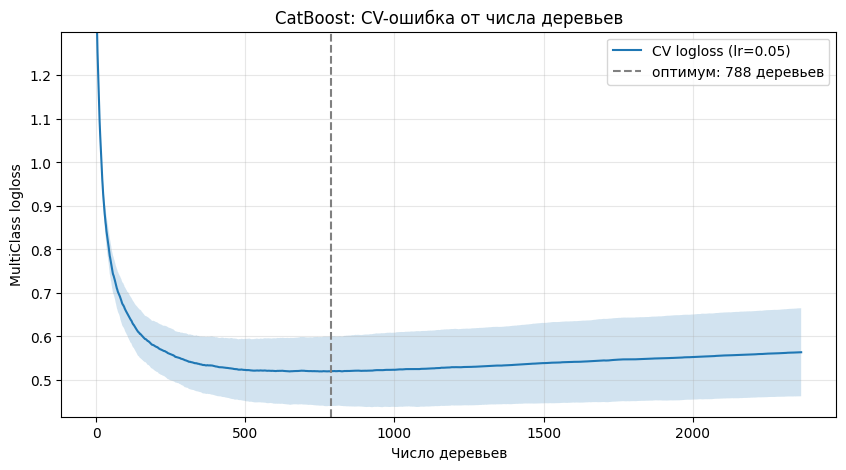

CatBoost (test): accuracy = 0.7710, f1 (macro) = 0.7690


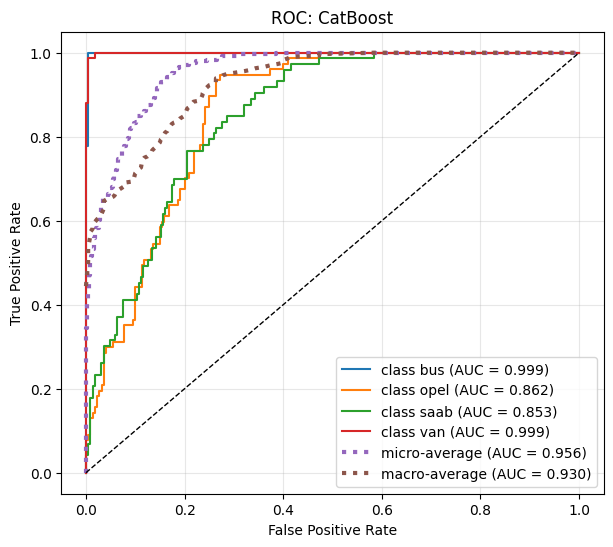

,model,accuracy,f1 macro
0,Logistic regression,0.8081,0.8065
1,Logistic regression + PCA,0.6229,0.6145
2,Decision tree,0.7037,0.7086
3,Bagging LR (N=100),0.8047,0.8023
4,Bagging DT (N=100),0.7677,0.7627
5,Random forest (27),0.7576,0.7535
6,CatBoost (788),0.7710,0.7690


In [33]:
from catboost import Pool, CatBoost, cv as cb_cv

train_pool = Pool(X_train_f, label=y_train_enc)
test_pool = Pool(X_test_f, label=y_test_enc)
base_params = {
    'loss_function': 'MultiClass',
    'eval_metric': 'MultiClass',
    'depth': 6,
    'l2_leaf_reg': 3,
    'random_seed': RANDOM_STATE,
    'logging_level': 'Silent',
    'allow_writing_files': False,
}

#Число деревьев подбираем 5-fold CV с ранней остановкой: на каждой итерации считаем CV-logloss, оптимум = итерация с минимальным значением. Дополнительно — небольшая сетка по learning_rate.
cv_results = []
for lr_rate in [0.3, 0.1, 0.05]:
    params = {**base_params, 'learning_rate': lr_rate, 'iterations': 3000}
    cv_df = cb_cv(train_pool, params, fold_count=5, stratified=True, shuffle=True, seed=RANDOM_STATE,
                  early_stopping_rounds=100, logging_level='Silent')
    curve = cv_df['test-MultiClass-mean'].values
    best_it = int(np.argmin(curve))
    cv_results.append({'learning_rate': lr_rate, 'best n_trees': best_it + 1, 'CV logloss': curve[best_it]})
cv_results = pd.DataFrame(cv_results)
print(cv_results.round(4).to_string(index=False))

best = cv_results.loc[cv_results['CV logloss'].idxmin()]
BEST_LR, BEST_N = float(best['learning_rate']), int(best['best n_trees'])
print(f'\nЛучшее: learning_rate = {BEST_LR}, число деревьев = {BEST_N}')

#Кривая CV-ошибки от числа деревьев (без ранней остановки, чтобы увидеть переобучение)
cv_long = cb_cv(train_pool, {**base_params, 'learning_rate': BEST_LR, 'iterations': BEST_N * 3},
                fold_count=5, stratified=True, shuffle=True, seed=RANDOM_STATE, logging_level='Silent')
mean = cv_long['test-MultiClass-mean'].values; std = cv_long['test-MultiClass-std'].values
it = np.arange(1, len(mean) + 1)
plt.figure(figsize=(10, 5))
plt.plot(it, mean, label=f'CV logloss (lr={BEST_LR})')
plt.fill_between(it, mean - std, mean + std, alpha=.2)
plt.axvline(BEST_N, ls='--', color='grey', label=f'оптимум: {BEST_N} деревьев')
plt.ylim(mean.min() * 0.8, mean.min() * 2.5)
plt.xlabel('Число деревьев'); plt.ylabel('MultiClass logloss'); plt.title('CatBoost: CV-ошибка от числа деревьев')
plt.legend(); plt.grid(alpha=.3); plt.show()

#Финальная модель на всём train с найденным числом деревьев
booster = CatBoost({**base_params, 'learning_rate': BEST_LR, 'iterations': BEST_N})
booster.fit(train_pool)
gb_proba = booster.predict(test_pool, prediction_type='Probability')
gb_pred = gb_proba.argmax(axis=1)
gb_acc = accuracy_score(y_test_enc, gb_pred); gb_f1 = f1_score(y_test_enc, gb_pred, average='macro')
print(f'CatBoost (test): accuracy = {gb_acc:.4f}, f1 (macro) = {gb_f1:.4f}')
plot_multiclass_roc(y_test_enc, gb_proba, title='ROC: CatBoost')

#Итоговое сравнение всех моделей
summary = pd.DataFrame([
    ('Logistic regression', lr_acc, lr_f1),
    ('Logistic regression + PCA', lr_pca_acc, lr_pca_f1),
    ('Decision tree', dt_acc, dt_f1),
    ('Bagging LR (N=100)', bag_lr_acc[-1], bag_lr_f1[-1]),
    ('Bagging DT (N=100)', bag_dt_acc[-1], bag_dt_f1[-1]),
    (f'Random forest ({RF_N_TREES})', rf_acc_best, rf_f1_best),
    (f'CatBoost ({BEST_N})', gb_acc, gb_f1),
], columns=['model', 'accuracy', 'f1 macro']).round(4)
summary

**Выводы по 2.9.** 

* Число деревьев подбиралось 5-fold кросс-валидацией (`catboost.cv`) с ранней остановкой: на каждой итерации бустинга считается CV-logloss, и оптимум — итерация с минимальной ошибкой. Дополнительно перебирался `learning_rate`.
* Чем меньше `learning_rate`, тем больше деревьев нужно.
* Кривая CV-ошибки на графике U-образная. Сначала ошибка быстро падает, затем после оптимума медленно растёт. В отличие от бэггинга и RF, **бустинг переобучается при избыточном числе деревьев**: каждое новое дерево подгоняется под остатки, то есть под шум обучающей выборки. Поэтому число деревьев здесь — важный гиперпараметр, который нужно подбирать по валидации.
* При выбранном `learning_rate` оптимальное число деревьев **~788** при lr=0.05. На test CatBoost даёт accuracy = 0.77: это лучше одиночного дерева, на уровне бэггинга деревьев и RF или чуть выше, но ниже логистической регрессии.
* По итоговой таблице лучшая модель на этих данных — логистическая регрессия на стандартизованных признаках (с бэггингом или без). Это согласуется с learning curve: при ~550 объектах простая линейная модель эффективнее моделей на деревьях.